# Plot a figure displaying our 3 different hypotheses

In [2]:
import numpy as np
from pathlib import Path
import os, sys
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import warnings
import pandas as pd
import json

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDMODEL/Data_SoundGOOD/LEAD_ExperimentalFolder")
os.chdir(repo_root)

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.environ["PYTHONPATH"] = str(repo_root) + os.pathsep + os.environ.get("PYTHONPATH", "")

import LEAD as lead


# Important variables
cwd = Path.cwd()
SNRs = np.array([-np.inf,-13,-11,-9,-7,-5,-3])
SubIDs = ['01','02','03','05','06','07','08','09','11','12','13','14','15','17','19','20','22','23','24','25']
colormap = {0: (0, 0, 0), 1: (0, 0.25, 1), 2: (0, 0.9375, 1), 3: (0, 0.91, 0.1), 4: (1, 0.6, 0), 5: (1, 0, 0), 6: (0.8, 0, 0)}

Linear                       MetaScore = -1.00e-02 (−∞ dB, x = -0.00) | means:  0.01  0.45  0.88  1.32  1.75  2.20
Fixed Gain (bistable)        MetaScore = -1.83e-05 (−13 dB, x = 1.49) | means: -0.00  0.44  0.88  1.31  1.75  2.19
Modulated Gain (metastable)  MetaScore = -4.61e-13 (−11 dB, x = 1.28) | means: -0.00  0.44  0.88  1.30  1.76  2.20


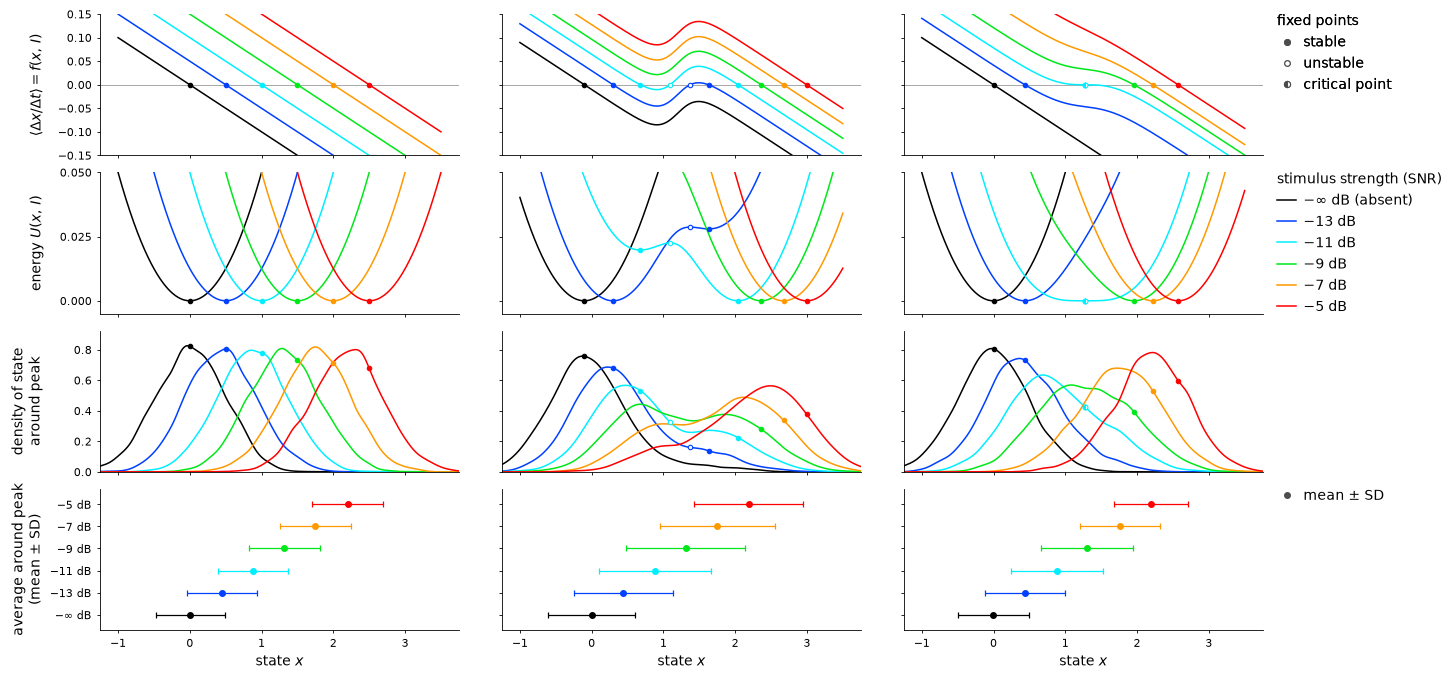

In [3]:
import sys
import warnings
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import ConnectionPatch
from scipy.integrate import cumulative_trapezoid
from scipy.stats import gaussian_kde

LEAD_PARENT = Path(r"C:\Users\thoma\path\to\folder\containing\LEAD")
if LEAD_PARENT.exists() and str(LEAD_PARENT) not in sys.path:
    sys.path.insert(0, str(LEAD_PARENT))

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    import LEAD as lead

OUT = Path("fig_linear_bistable_metastable_energy")
SEED = 0
N_TRIALS = 5000
BASELINE_STEPS = 100
STIM_STEPS = 25
AVG_STEPS = 10

SHOW_EQ_LINES = False  # <-- True / False : affiche ou masque les lignes pointillées reliant les équilibres
SHOW_AVG_ROW = True   # <-- True / False : ajoute ou retire la 4e ligne (moyenne autour du pic par SNR)

CATEGORIES = list(range(6))
SNR_LABELS = ["−∞ dB", "−13 dB", "−11 dB", "−9 dB", "−7 dB", "−5 dB"]
TAU = 10
PROCESS_NOISE = 0.25
MEASURE_NOISE = 0.1
SHARPNESS = 7

W_LINEAR = {f"w{k}": 0.05 * k for k in CATEGORIES}

# Weights calibrated so that mean activity around peak matches the linear model
THRESHOLD_BISTABLE = 1.2
GAIN_BISTABLE = 0.14
W_BISTABLE = {f"w{k}": w for k, w in zip(CATEGORIES, (-0.0103, 0.0295, 0.0644, 0.0963, 0.1274, 0.1596))}

# Critical example placed exactly at the cusp: g2 = 4 / (S * tau) => df/dx <= 0 everywhere, for every SNR
# (lower sharpness than the bistable model -> larger cusp gain and flatter drift around the critical point)
CRITICAL_CAT = 2
SHARPNESS_MODULATED = 4
THRESHOLD_MODULATED = 1.2758
GAIN_CUSP = 4 / (SHARPNESS_MODULATED * TAU)
GAINS_MODULATED = {f"g{k}": r * GAIN_CUSP for k, r in zip(CATEGORIES, (0.0, 0.8, 1.0, 0.8, 0.5, 0.25))}
W_MODULATED = {f"w{k}": w for k, w in zip(CATEGORIES, (0.0, 0.0410, None, 0.1206, 0.1730, 0.2324))}
W_MODULATED[f"w{CRITICAL_CAT}"] = THRESHOLD_MODULATED / TAU - GAIN_CUSP / 2  # f = df/dx = 0 at x = threshold

X_DRIFT = np.linspace(-1, 3.5, 2000)
X_KDE = np.linspace(-1.25, 3.75, 600)
XLIM = (-1.25, 3.75)
YLIM_DRIFT = (-0.15, 0.15)
YLIM_ENERGY = (-0.005, 0.05)

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
})


def build_models():
    common = dict(tau=TAU, process_noise=PROCESS_NOISE, measure_noise=MEASURE_NOISE)
    linear = lead.model.StratifiedLinear(**common, **W_LINEAR)
    bistable = lead.model.StratifiedNonLinear1(**common, gain=GAIN_BISTABLE, threshold=THRESHOLD_BISTABLE,
                                               sharpness=SHARPNESS, **W_BISTABLE)
    metastable = lead.model.StratifiedGainModulation(**common, threshold=THRESHOLD_MODULATED, sharpness=SHARPNESS_MODULATED,
                                                     **W_MODULATED, **GAINS_MODULATED)
    return [
        dict(name="Linear", model=linear, metastable=False),
        dict(name="Fixed Gain (bistable)", model=bistable, metastable=False),
        dict(name="Modulated Gain (metastable)", model=metastable, metastable=True),
    ]


def drift(model, x, cat):
    return model.core(x, np.ones_like(x), cat) - x


def energy(x, f):
    u = -cumulative_trapezoid(f, x, initial=0)
    inside = (x >= XLIM[0]) & (x <= XLIM[1])
    return u - u[inside].min()


def equilibria(x, f):
    idx = np.where(np.diff(np.sign(f)) != 0)[0]
    out = []
    for i in idx:
        x0 = x[i] - f[i] * (x[i + 1] - x[i]) / (f[i + 1] - f[i])
        out.append((x0, f[i + 1] < f[i]))
    return out


def meta_score(x, f):
    fp = np.gradient(f, x)
    d = f ** 2 + fp ** 2
    i = np.argmin(d)
    return -d[i], x[i]


def simulate(model):
    one_input = np.concatenate((np.zeros(BASELINE_STEPS), np.ones(STIM_STEPS + 1)))
    inputs = {cat: np.tile(one_input, (N_TRIALS, 1)) for cat in CATEGORIES}
    sims = model.measure_simulations(input_series=inputs)
    return {cat: sims[cat][:, -AVG_STEPS:].mean(1) for cat in CATEGORIES}


np.random.seed(SEED)
panels = build_models()

for p in panels:
    p["drift"] = {c: drift(p["model"], X_DRIFT, c) for c in CATEGORIES}
    p["energy"] = {c: energy(X_DRIFT, p["drift"][c]) for c in CATEGORIES}
    scores = [meta_score(X_DRIFT, p["drift"][c]) for c in CATEGORIES]
    best = int(np.argmax([s[0] for s in scores]))
    p["meta"], p["ghost_x"], p["ghost_cat"] = scores[best][0], scores[best][1], best
    p["avgs"] = simulate(p["model"])
    p["kde"] = {c: gaussian_kde(p["avgs"][c])(X_KDE) for c in CATEGORIES}
    p["eq"] = {c: [(x0, st) for x0, st in equilibria(X_DRIFT, p["drift"][c]) if XLIM[0] < x0 < XLIM[1]]
               for c in CATEGORIES}
    if p["metastable"]:
        p["eq"][best] = [(x0, st) for x0, st in p["eq"][best] if abs(x0 - p["ghost_x"]) > 0.05]
    means = " ".join(f"{p['avgs'][c].mean():5.2f}" for c in CATEGORIES)
    print(f"{p['name']:<28s} MetaScore = {p['meta']:.2e} ({SNR_LABELS[best]}, x = {p['ghost_x']:.2f})"
          f" | means: {means}")

n_rows = 4 if SHOW_AVG_ROW else 3
fig, axes = plt.subplots(n_rows, 3, figsize=(15, 2.0 * n_rows), sharex=True,
                         gridspec_kw=dict(height_ratios=[1] * n_rows, hspace=0.12, wspace=0.12))


def mark_fixed_points(ax, p, cat, yfun):
    color = lead.visual.colormap(cat)
    for x0, stable in p["eq"][cat]:
        ax.plot(x0, yfun(x0), "o", ms=3.2, mew=0.8, mec=color,
                mfc=color if stable else "white", zorder=4, clip_on=False)
    if p["metastable"] and cat == p["ghost_cat"]:
        ax.plot(p["ghost_x"], yfun(p["ghost_x"]), "o", ms=3.6, mew=0.8, mec=color, mfc=color,
                fillstyle="left", markerfacecoloralt="white", zorder=5, clip_on=False)


def kde_at(p, cat, x):
    return np.interp(x, X_KDE, p["kde"][cat])


for j, p in enumerate(panels):
    ax = axes[0, j]
    ax.axhline(0, color="0.6", lw=0.6, zorder=0)
    for cat in CATEGORIES:
        ax.plot(X_DRIFT, p["drift"][cat], color=lead.visual.colormap(cat))
        mark_fixed_points(ax, p, cat, lambda x: 0.0)
    ax.set_ylim(*YLIM_DRIFT)
    ax.set_yticks([-0.15, -0.1, -0.05, 0, 0.05, 0.1, 0.15])
    if j == 0:
        ax.set_ylabel(r"$\langle \Delta x / \Delta t \rangle = f(x,\,I)$")
    else:
        ax.tick_params(labelleft=False)

for j, p in enumerate(panels):
    ax = axes[1, j]
    for cat in CATEGORIES:
        u = p["energy"][cat]
        ax.plot(X_DRIFT, u, color=lead.visual.colormap(cat))
        mark_fixed_points(ax, p, cat, lambda x, u=u: np.interp(x, X_DRIFT, u))
    ax.set_ylim(*YLIM_ENERGY)
    ax.set_yticks([0, 0.025, 0.05])
    if j == 0:
        ax.set_ylabel(r"energy $U(x,\,I)$")
    else:
        ax.tick_params(labelleft=False)

dens_max = max(p["kde"][c].max() for p in panels for c in CATEGORIES)
for j, p in enumerate(panels):
    ax = axes[2, j]
    for cat in CATEGORIES:
        ax.plot(X_KDE, p["kde"][cat], color=lead.visual.colormap(cat))
        mark_fixed_points(ax, p, cat, lambda x, p=p, cat=cat: kde_at(p, cat, x))
    ax.set_ylim(0, dens_max * 1.12)
    if j == 0:
        ax.set_ylabel("density of state\naround peak")
    else:
        ax.tick_params(labelleft=False)

if SHOW_AVG_ROW:
    for j, p in enumerate(panels):
        ax = axes[3, j]
        for cat in CATEGORIES:
            a = p["avgs"][cat]
            ax.errorbar(a.mean(), cat, xerr=a.std(), fmt="o", ms=4, color=lead.visual.colormap(cat),
                        elinewidth=0.9, capsize=2, capthick=0.9, zorder=3)
        ax.set_ylim(-0.7, len(CATEGORIES) - 0.3)
        ax.set_yticks(CATEGORIES)
        if j == 0:
            ax.set_yticklabels(SNR_LABELS)
            ax.set_ylabel("average around peak\n(mean ± SD)")
        else:
            ax.tick_params(labelleft=False)

for ax in axes[-1]:
    ax.set_xlabel(r"state $x$")
for ax in axes.flat:
    ax.set_xlim(*XLIM)
    ax.set_facecolor("none")

if SHOW_EQ_LINES:
    for j, p in enumerate(panels):
        for cat in CATEGORIES:
            xs = [x0 for x0, _ in p["eq"][cat]]
            if p["metastable"] and cat == p["ghost_cat"]:
                xs.append(p["ghost_x"])
            for x0 in xs:
                fig.add_artist(ConnectionPatch(xyA=(x0, 0), coordsA=axes[0, j].transData,
                                               xyB=(x0, kde_at(p, cat, x0)), coordsB=axes[2, j].transData,
                                               color=lead.visual.colormap(cat), lw=0.6, ls=(0, (3, 2)),
                                               alpha=0.7, zorder=-1))

eq_handles = [
    Line2D([], [], ls="", marker="o", ms=4, mfc="0.3", mec="0.3", label="stable"),
    Line2D([], [], ls="", marker="o", ms=4, mfc="white", mec="0.3", mew=0.8, label="unstable"),
    Line2D([], [], ls="", marker="o", ms=4.4, mfc="0.3", mec="0.3", mew=0.8, fillstyle="left",
           markerfacecoloralt="white", label="critical point"),
]
stim_handles = [Line2D([], [], color=lead.visual.colormap(c), label=SNR_LABELS[c]) for c in CATEGORIES]
stim_handles[0].set_label("−∞ dB (absent)")

legend_kw = dict(loc="upper left", frameon=False, alignment="left", borderaxespad=0,
                 borderpad=0, handlelength=1.4, handletextpad=0.5)
leg_eq = axes[0, 2].legend(handles=eq_handles, title="fixed points",
                           bbox_to_anchor=(1.04, 1.0), **legend_kw)
axes[0, 2].add_artist(leg_eq)
axes[1, 2].legend(handles=stim_handles, title="stimulus strength (SNR)",
                  bbox_to_anchor=(1.04, 1.0), **legend_kw)
if SHOW_AVG_ROW:
    avg_handles = [Line2D([], [], ls="", marker="o", ms=4, color="0.3", label="mean ± SD")]
    axes[3, 2].legend(handles=avg_handles, bbox_to_anchor=(1.04, 1.0), **legend_kw)

fig.align_ylabels(axes[:, 0])
# fig.savefig(OUT.with_suffix(".pdf"), bbox_inches="tight", pad_inches=0.02)
# fig.savefig(OUT.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.02)
# fig.savefig(OUT.with_suffix(".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

Linear                       MetaScore = -1.00e-02 (−∞ dB, x = -0.00) | means: -0.01  0.44  0.87  1.33  1.75  2.20
Fixed Gain (bistable)        MetaScore = -1.83e-05 (−13 dB, x = 1.49) | means: -0.01  0.44  0.89  1.32  1.78  2.22
Modulated Gain (metastable)  MetaScore = -1.64e-07 (−11 dB, x = 1.47) | means:  0.02  0.45  0.90  1.33  1.76  2.19


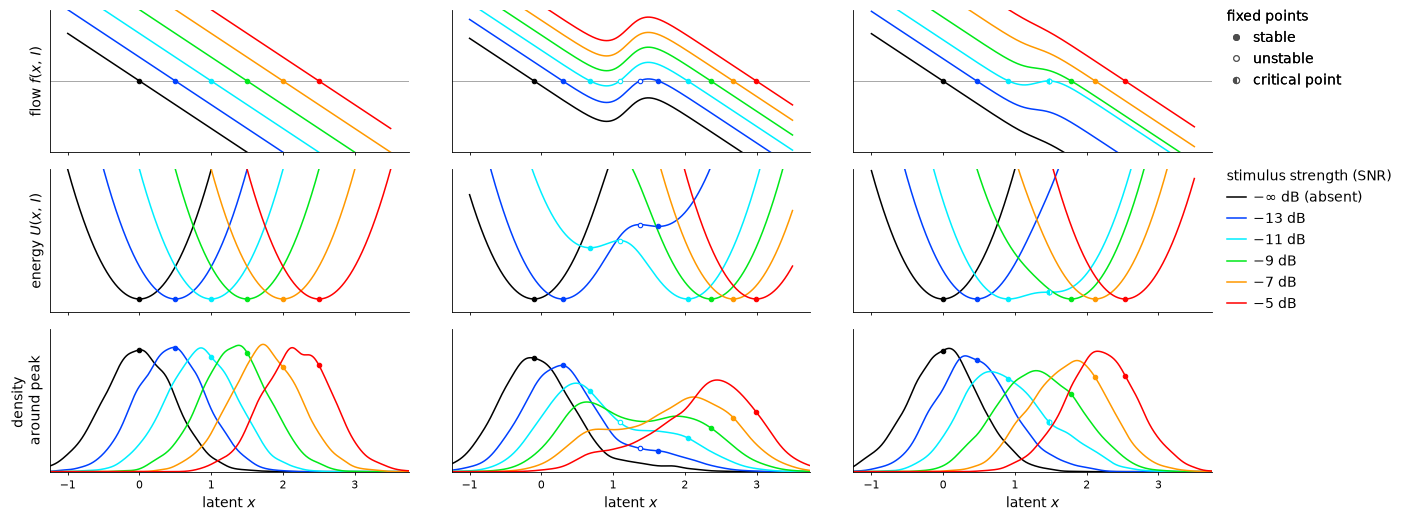

In [4]:
import sys
import warnings
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import ConnectionPatch
from scipy.integrate import cumulative_trapezoid
from scipy.stats import gaussian_kde

OUT = Path("fig_linear_bistable_metastable_energy")
SEED = 42
N_TRIALS = 5000
BASELINE_STEPS = 100
STIM_STEPS = 25
AVG_STEPS = 10

SHOW_EQ_LINES = False  # <-- True / False : affiche ou masque les lignes pointillées reliant les équilibres
SHOW_AVG_ROW = False   # <-- True / False : ajoute ou retire la 4e ligne (moyenne autour du pic par SNR)

CATEGORIES = list(range(6))
SNR_LABELS = ["−∞ dB", "−13 dB", "−11 dB", "−9 dB", "−7 dB", "−5 dB"]
TAU = 10
PROCESS_NOISE = 0.25
MEASURE_NOISE = 0.05
SHARPNESS = 7

W_LINEAR = {f"w{k}": 0.05 * k for k in CATEGORIES}

# Weights calibrated so that mean activity around peak matches the linear model
THRESHOLD_BISTABLE = 1.2
GAIN_BISTABLE = 0.14
W_BISTABLE = {f"w{k}": w for k, w in zip(CATEGORIES, (-0.0103, 0.0295, 0.0644, 0.0963, 0.1274, 0.1596))}

THRESHOLD_MODULATED = 1.3
GAINS_MODULATED = {f"g{k}": g for k, g in zip(CATEGORIES, (0.02, 0.0463, 0.0794, 0.0463, 0.0265, 0.0132))}
W_MODULATED = {f"w{k}": w for k, w in zip(CATEGORIES, (-0.0005, 0.0465, None, 0.1337, 0.1854, 0.2404))}
CRITICAL_CAT = 2


def critical_weight(gain, threshold):
    u = 2 / SHARPNESS * np.arccosh(np.sqrt(gain * SHARPNESS * TAU / 4))
    return (threshold + u) / TAU - gain / (1 + np.exp(-SHARPNESS * u))


W_MODULATED[f"w{CRITICAL_CAT}"] = critical_weight(GAINS_MODULATED[f"g{CRITICAL_CAT}"], THRESHOLD_MODULATED)

X_DRIFT = np.linspace(-1, 3.5, 2000)
X_KDE = np.linspace(-1.25, 3.75, 600)
XLIM = (-1.25, 3.75)
YLIM_DRIFT = (-0.15, 0.15)
YLIM_ENERGY = (-0.005, 0.05)

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
})


def build_models():
    common = dict(tau=TAU, process_noise=PROCESS_NOISE, measure_noise=MEASURE_NOISE)
    linear = lead.model.StratifiedLinear(**common, **W_LINEAR)
    bistable = lead.model.StratifiedNonLinear1(**common, gain=GAIN_BISTABLE, threshold=THRESHOLD_BISTABLE,
                                               sharpness=SHARPNESS, **W_BISTABLE)
    metastable = lead.model.StratifiedGainModulation(**common, threshold=THRESHOLD_MODULATED, sharpness=SHARPNESS,
                                                     **W_MODULATED, **GAINS_MODULATED)
    return [
        dict(name="Linear", model=linear, metastable=False),
        dict(name="Fixed Gain (bistable)", model=bistable, metastable=False),
        dict(name="Modulated Gain (metastable)", model=metastable, metastable=True),
    ]


def drift(model, x, cat):
    return model.core(x, np.ones_like(x), cat) - x


def energy(x, f):
    u = -cumulative_trapezoid(f, x, initial=0)
    inside = (x >= XLIM[0]) & (x <= XLIM[1])
    return u - u[inside].min()


def equilibria(x, f):
    idx = np.where(np.diff(np.sign(f)) != 0)[0]
    out = []
    for i in idx:
        x0 = x[i] - f[i] * (x[i + 1] - x[i]) / (f[i + 1] - f[i])
        out.append((x0, f[i + 1] < f[i]))
    return out


def meta_score(x, f):
    fp = np.gradient(f, x)
    d = f ** 2 + fp ** 2
    i = np.argmin(d)
    return -d[i], x[i]


def simulate(model):
    one_input = np.concatenate((np.zeros(BASELINE_STEPS), np.ones(STIM_STEPS + 1)))
    inputs = {cat: np.tile(one_input, (N_TRIALS, 1)) for cat in CATEGORIES}
    sims = model.measure_simulations(input_series=inputs)
    return {cat: sims[cat][:, -AVG_STEPS:].mean(1) for cat in CATEGORIES}


np.random.seed(SEED)
panels = build_models()

for p in panels:
    p["drift"] = {c: drift(p["model"], X_DRIFT, c) for c in CATEGORIES}
    p["energy"] = {c: energy(X_DRIFT, p["drift"][c]) for c in CATEGORIES}
    scores = [meta_score(X_DRIFT, p["drift"][c]) for c in CATEGORIES]
    best = int(np.argmax([s[0] for s in scores]))
    p["meta"], p["ghost_x"], p["ghost_cat"] = scores[best][0], scores[best][1], best
    p["avgs"] = simulate(p["model"])
    p["kde"] = {c: gaussian_kde(p["avgs"][c])(X_KDE) for c in CATEGORIES}
    p["eq"] = {c: [(x0, st) for x0, st in equilibria(X_DRIFT, p["drift"][c]) if XLIM[0] < x0 < XLIM[1]]
               for c in CATEGORIES}
    means = " ".join(f"{p['avgs'][c].mean():5.2f}" for c in CATEGORIES)
    print(f"{p['name']:<28s} MetaScore = {p['meta']:.2e} ({SNR_LABELS[best]}, x = {p['ghost_x']:.2f})"
          f" | means: {means}")

n_rows = 4 if SHOW_AVG_ROW else 3
fig, axes = plt.subplots(n_rows, 3, figsize=(15, 2.0 * n_rows), sharex=True,
                         gridspec_kw=dict(height_ratios=[1] * n_rows, hspace=0.12, wspace=0.12))


def mark_fixed_points(ax, p, cat, yfun):
    color = lead.visual.colormap(cat)
    for x0, stable in p["eq"][cat]:
        ax.plot(x0, yfun(x0), "o", ms=3.2, mew=0.8, mec=color,
                mfc=color if stable else "white", zorder=4, clip_on=False)
    if p["metastable"] and cat == p["ghost_cat"]:
        ax.plot(p["ghost_x"], yfun(p["ghost_x"]), "o", ms=3.6, mew=0.8, mec=color, mfc=color,
                fillstyle="left", markerfacecoloralt="white", zorder=5, clip_on=False)


def kde_at(p, cat, x):
    return np.interp(x, X_KDE, p["kde"][cat])


for j, p in enumerate(panels):
    ax = axes[0, j]
    ax.axhline(0, color="0.6", lw=0.6, zorder=0)
    for cat in CATEGORIES:
        ax.plot(X_DRIFT, p["drift"][cat], color=lead.visual.colormap(cat))
        mark_fixed_points(ax, p, cat, lambda x: 0.0)
    ax.set_ylim(*YLIM_DRIFT)
    ax.set_yticks([]) #[-0.15, -0.1, -0.05, 0, 0.05, 0.1, 0.15])
    if j == 0:
        ax.set_ylabel(r"flow $f(x,\,I)$")
    else:
        ax.tick_params(labelleft=False)

for j, p in enumerate(panels):
    ax = axes[1, j]
    for cat in CATEGORIES:
        u = p["energy"][cat]
        ax.plot(X_DRIFT, u, color=lead.visual.colormap(cat))
        mark_fixed_points(ax, p, cat, lambda x, u=u: np.interp(x, X_DRIFT, u))
    ax.set_ylim(*YLIM_ENERGY)
    ax.set_yticks([]) #[0, 0.02, 0.04])
    if j == 0:
        ax.set_ylabel(r"energy $U(x,\,I)$")
    else:
        ax.tick_params(labelleft=False)

dens_max = max(p["kde"][c].max() for p in panels for c in CATEGORIES)
for j, p in enumerate(panels):
    ax = axes[2, j]
    for cat in CATEGORIES:
        ax.plot(X_KDE, p["kde"][cat], color=lead.visual.colormap(cat))
        mark_fixed_points(ax, p, cat, lambda x, p=p, cat=cat: kde_at(p, cat, x))
    ax.set_ylim(0, dens_max * 1.12)
    ax.set_yticks([])
    if j == 0:
        ax.set_ylabel("density \naround peak")
    else:
        ax.tick_params(labelleft=False)

if SHOW_AVG_ROW:
    for j, p in enumerate(panels):
        ax = axes[3, j]
        for cat in CATEGORIES:
            a = p["avgs"][cat]
            ax.errorbar(a.mean(), cat, xerr=a.std(), fmt="o", ms=4, color=lead.visual.colormap(cat),
                        elinewidth=0.9, capsize=2, capthick=0.9, zorder=3)
        ax.set_ylim(-0.7, len(CATEGORIES) - 0.3)
        ax.set_yticks([]) #ax.set_yticks(CATEGORIES)
        if j == 0:
            # ax.set_yticklabels(SNR_LABELS)
            ax.set_ylabel("average \naround peak")
        else:
            ax.tick_params(labelleft=False)

for ax in axes[-1]:
    ax.set_xlabel(r"latent $x$")
for ax in axes.flat:
    ax.set_xlim(*XLIM)
    ax.set_facecolor("none")

if SHOW_EQ_LINES:
    for j, p in enumerate(panels):
        for cat in CATEGORIES:
            xs = [x0 for x0, _ in p["eq"][cat]]
            if p["metastable"] and cat == p["ghost_cat"]:
                xs.append(p["ghost_x"])
            for x0 in xs:
                fig.add_artist(ConnectionPatch(xyA=(x0, 0), coordsA=axes[0, j].transData,
                                               xyB=(x0, kde_at(p, cat, x0)), coordsB=axes[2, j].transData,
                                               color=lead.visual.colormap(cat), lw=0.6, ls=(0, (3, 2)),
                                               alpha=0.7, zorder=-1))

eq_handles = [
    Line2D([], [], ls="", marker="o", ms=4, mfc="0.3", mec="0.3", label="stable"),
    Line2D([], [], ls="", marker="o", ms=4, mfc="white", mec="0.3", mew=0.8, label="unstable"),
    Line2D([], [], ls="", marker="o", ms=4.4, mfc="0.3", mec="0.3", mew=0.8, fillstyle="left",
           markerfacecoloralt="white", label="critical point"),
]
stim_handles = [Line2D([], [], color=lead.visual.colormap(c), label=SNR_LABELS[c]) for c in CATEGORIES]
stim_handles[0].set_label("−∞ dB (absent)")

legend_kw = dict(loc="upper left", frameon=False, alignment="left", borderaxespad=0,
                 borderpad=0, handlelength=1.4, handletextpad=0.5)
leg_eq = axes[0, 2].legend(handles=eq_handles, title="fixed points",
                           bbox_to_anchor=(1.04, 1.0), **legend_kw)
axes[0, 2].add_artist(leg_eq)
axes[1, 2].legend(handles=stim_handles, title="stimulus strength (SNR)",
                  bbox_to_anchor=(1.04, 1.0), **legend_kw)
if SHOW_AVG_ROW:
    avg_handles = [Line2D([], [], ls="", marker="o", ms=4, color="0.3", label="mean ± SD")]
    axes[3, 2].legend(handles=avg_handles, bbox_to_anchor=(1.04, 1.0), **legend_kw)

fig.align_ylabels(axes[:, 0])
# fig.savefig(OUT.with_suffix(".pdf"), bbox_inches="tight", pad_inches=0.02)
# fig.savefig(OUT.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.02)
# fig.savefig(OUT.with_suffix(".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

Linear (leaky DDM)   equilibria: -0.00 | 0.50 | 1.00 | 1.50 | 2.00 | 2.50
                     means: -0.01  0.44  0.87  1.33  1.75  2.20
Fixed Gain           equilibria: -0.10 | 0.30,1.37,1.63 | 0.68,1.09,2.04 | 2.36 | 2.67 | 3.00
                     means: -0.01  0.44  0.89  1.32  1.78  2.22
Modulated Gain       equilibria: -0.10 | 0.30,1.37,1.63 | 0.63,1.10,2.10 | 2.36 | 2.67 | 3.00
                     means: -0.07  0.40  0.80  1.64  2.20  2.58


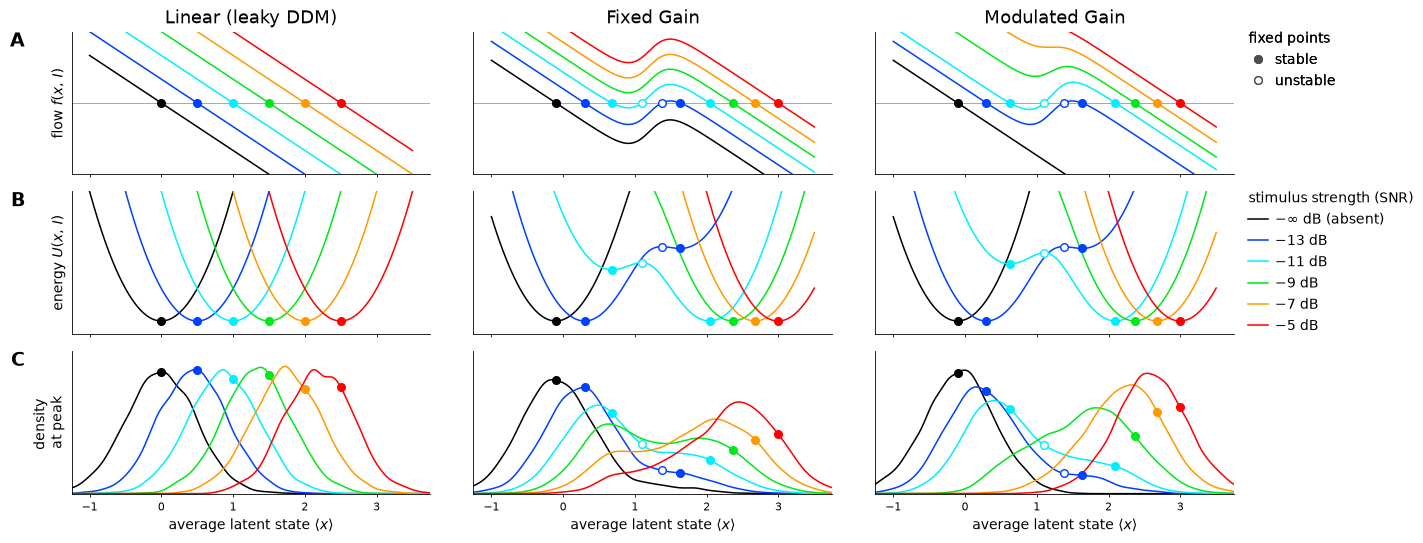

In [8]:
import sys
import warnings
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import ConnectionPatch
from scipy.integrate import cumulative_trapezoid
from scipy.stats import gaussian_kde

OUT = Path("fig_linear_bistable_metastable_energy_v3")
SEED = 42
N_TRIALS = 5000
BASELINE_STEPS = 100
STIM_STEPS = 25
AVG_STEPS = 10

SHOW_EQ_LINES = False  # <-- True / False : affiche ou masque les lignes pointillées reliant les équilibres
SHOW_AVG_ROW = False   # <-- True / False : ajoute ou retire la 4e ligne (moyenne autour du pic par SNR)

CATEGORIES = list(range(6))
SNR_LABELS = ["−∞ dB", "−13 dB", "−11 dB", "−9 dB", "−7 dB", "−5 dB"]
TAU = 10
PROCESS_NOISE = 0.25
MEASURE_NOISE = 0.05
SHARPNESS = 7

W_LINEAR = {f"w{k}": 0.05 * k for k in CATEGORIES}

# Weights calibrated so that mean activity around peak matches the linear model
THRESHOLD_BISTABLE = 1.2
GAIN_BISTABLE = 0.14
W_BISTABLE = {f"w{k}": w for k, w in zip(CATEGORIES, (-0.0103, 0.0295, 0.0644, 0.0963, 0.1274, 0.1596))}

# Inverted-U gains; weights solved so that fixed points match the Fixed Gain model (within 0.06)
THRESHOLD_MODULATED = THRESHOLD_BISTABLE
GAINS_MODULATED = {f"g{k}": g for k, g in zip(CATEGORIES, (0, 0.14, 0.15, 0.10, 0.06, 0.03))}
W_MODULATED = {f"w{k}": w for k, w in zip(CATEGORIES, (-0.0103, 0.0295, 0.0599, 0.1363, 0.2074, 0.2696))}

FP_MS = 5.5
TITLES = ["Linear (leaky DDM)", "Fixed Gain", "Modulated Gain"]

X_DRIFT = np.linspace(-1, 3.5, 2000)
X_KDE = np.linspace(-1.25, 3.75, 600)
XLIM = (-1.25, 3.75)
YLIM_DRIFT = (-0.15, 0.15)
YLIM_ENERGY = (-0.005, 0.05)

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
})


def build_models():
    common = dict(tau=TAU, process_noise=PROCESS_NOISE, measure_noise=MEASURE_NOISE)
    linear = lead.model.StratifiedLinear(**common, **W_LINEAR)
    bistable = lead.model.StratifiedNonLinear1(**common, gain=GAIN_BISTABLE, threshold=THRESHOLD_BISTABLE,
                                               sharpness=SHARPNESS, **W_BISTABLE)
    metastable = lead.model.StratifiedGainModulation(**common, threshold=THRESHOLD_MODULATED, sharpness=SHARPNESS,
                                                     **W_MODULATED, **GAINS_MODULATED)
    return [dict(name=t, model=m) for t, m in zip(TITLES, (linear, bistable, metastable))]


def drift(model, x, cat):
    return model.core(x, np.ones_like(x), cat) - x


def energy(x, f):
    u = -cumulative_trapezoid(f, x, initial=0)
    inside = (x >= XLIM[0]) & (x <= XLIM[1])
    return u - u[inside].min()


def equilibria(x, f):
    idx = np.where(np.diff(np.sign(f)) != 0)[0]
    out = []
    for i in idx:
        x0 = x[i] - f[i] * (x[i + 1] - x[i]) / (f[i + 1] - f[i])
        out.append((x0, f[i + 1] < f[i]))
    return out


def simulate(model):
    one_input = np.concatenate((np.zeros(BASELINE_STEPS), np.ones(STIM_STEPS + 1)))
    inputs = {cat: np.tile(one_input, (N_TRIALS, 1)) for cat in CATEGORIES}
    sims = model.measure_simulations(input_series=inputs)
    return {cat: sims[cat][:, -AVG_STEPS:].mean(1) for cat in CATEGORIES}


np.random.seed(SEED)
panels = build_models()

for p in panels:
    p["drift"] = {c: drift(p["model"], X_DRIFT, c) for c in CATEGORIES}
    p["energy"] = {c: energy(X_DRIFT, p["drift"][c]) for c in CATEGORIES}
    p["avgs"] = simulate(p["model"])
    p["kde"] = {c: gaussian_kde(p["avgs"][c])(X_KDE) for c in CATEGORIES}
    p["eq"] = {c: [(x0, st) for x0, st in equilibria(X_DRIFT, p["drift"][c]) if XLIM[0] < x0 < XLIM[1]]
               for c in CATEGORIES}
    means = " ".join(f"{p['avgs'][c].mean():5.2f}" for c in CATEGORIES)
    eqs = " | ".join(",".join(f"{x0:.2f}" for x0, _ in p["eq"][c]) for c in CATEGORIES)
    print(f"{p['name']:<20s} equilibria: {eqs}\n{'':<20s} means: {means}")

n_rows = 4 if SHOW_AVG_ROW else 3
fig, axes = plt.subplots(n_rows, 3, figsize=(15, 2.0 * n_rows), sharex=True,
                         gridspec_kw=dict(height_ratios=[1] * n_rows, hspace=0.12, wspace=0.12))


def mark_fixed_points(ax, p, cat, yfun):
    color = lead.visual.colormap(cat)
    for x0, stable in p["eq"][cat]:
        ax.plot(x0, yfun(x0), "o", ms=FP_MS, mew=1.0, mec=color,
                mfc=color if stable else "white", zorder=4, clip_on=False)


def kde_at(p, cat, x):
    return np.interp(x, X_KDE, p["kde"][cat])


for j, p in enumerate(panels):
    ax = axes[0, j]
    ax.set_title(p["name"])
    ax.axhline(0, color="0.6", lw=0.6, zorder=0)
    for cat in CATEGORIES:
        ax.plot(X_DRIFT, p["drift"][cat], color=lead.visual.colormap(cat))
        mark_fixed_points(ax, p, cat, lambda x: 0.0)
    ax.set_ylim(*YLIM_DRIFT)
    ax.set_yticks([]) #[-0.15, -0.1, -0.05, 0, 0.05, 0.1, 0.15])
    if j == 0:
        ax.set_ylabel(r"flow $f(x,\,I)$")
    else:
        ax.tick_params(labelleft=False)

for j, p in enumerate(panels):
    ax = axes[1, j]
    for cat in CATEGORIES:
        u = p["energy"][cat]
        ax.plot(X_DRIFT, u, color=lead.visual.colormap(cat))
        mark_fixed_points(ax, p, cat, lambda x, u=u: np.interp(x, X_DRIFT, u))
    ax.set_ylim(*YLIM_ENERGY)
    ax.set_yticks([]) #[0, 0.02, 0.04])
    if j == 0:
        ax.set_ylabel(r"energy $U(x,\,I)$")
    else:
        ax.tick_params(labelleft=False)

dens_max = max(p["kde"][c].max() for p in panels for c in CATEGORIES)
for j, p in enumerate(panels):
    ax = axes[2, j]
    for cat in CATEGORIES:
        ax.plot(X_KDE, p["kde"][cat], color=lead.visual.colormap(cat))
        mark_fixed_points(ax, p, cat, lambda x, p=p, cat=cat: kde_at(p, cat, x))
    ax.set_ylim(0, dens_max * 1.12)
    ax.set_yticks([])
    if j == 0:
        ax.set_ylabel("density \nat peak")
    else:
        ax.tick_params(labelleft=False)

if SHOW_AVG_ROW:
    for j, p in enumerate(panels):
        ax = axes[3, j]
        for cat in CATEGORIES:
            a = p["avgs"][cat]
            ax.errorbar(a.mean(), cat, xerr=a.std(), fmt="o", ms=4, color=lead.visual.colormap(cat),
                        elinewidth=0.9, capsize=2, capthick=0.9, zorder=3)
        ax.set_ylim(-0.7, len(CATEGORIES) - 0.3)
        ax.set_yticks([]) #ax.set_yticks(CATEGORIES)
        if j == 0:
            # ax.set_yticklabels(SNR_LABELS)
            ax.set_ylabel("average \naround peak")
        else:
            ax.tick_params(labelleft=False)

for ax in axes[-1]:
    ax.set_xlabel(r"average latent state $\langle x \rangle$")
for ax in axes.flat:
    ax.set_xlim(*XLIM)
    ax.set_facecolor("none")

if SHOW_EQ_LINES:
    for j, p in enumerate(panels):
        for cat in CATEGORIES:
            for x0, _ in p["eq"][cat]:
                fig.add_artist(ConnectionPatch(xyA=(x0, 0), coordsA=axes[0, j].transData,
                                               xyB=(x0, kde_at(p, cat, x0)), coordsB=axes[2, j].transData,
                                               color=lead.visual.colormap(cat), lw=0.6, ls=(0, (3, 2)),
                                               alpha=0.7, zorder=-1))

eq_handles = [
    Line2D([], [], ls="", marker="o", ms=FP_MS, mfc="0.3", mec="0.3", label="stable"),
    Line2D([], [], ls="", marker="o", ms=FP_MS, mfc="white", mec="0.3", mew=1.0, label="unstable"),
]
stim_handles = [Line2D([], [], color=lead.visual.colormap(c), label=SNR_LABELS[c]) for c in CATEGORIES]
stim_handles[0].set_label("−∞ dB (absent)")

legend_kw = dict(loc="upper left", frameon=False, alignment="left", borderaxespad=0,
                 borderpad=0, handlelength=1.4, handletextpad=0.5)
leg_eq = axes[0, 2].legend(handles=eq_handles, title="fixed points",
                           bbox_to_anchor=(1.04, 1.0), **legend_kw)
axes[0, 2].add_artist(leg_eq)
axes[1, 2].legend(handles=stim_handles, title="stimulus strength (SNR)",
                  bbox_to_anchor=(1.04, 1.0), **legend_kw)
if SHOW_AVG_ROW:
    avg_handles = [Line2D([], [], ls="", marker="o", ms=4, color="0.3", label="mean ± SD")]
    axes[3, 2].legend(handles=avg_handles, bbox_to_anchor=(1.04, 1.0), **legend_kw)

fig.align_ylabels(axes[:, 0])
for i, ax in enumerate(axes[:, 0]):
    ax.text(-0.13, 1.0, "ABCD"[i], transform=ax.transAxes, fontsize=14, fontweight="bold", va="top", ha="right")
# fig.savefig(OUT.with_suffix(".pdf"), bbox_inches="tight", pad_inches=0.02)
# fig.savefig(OUT.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.02)
fig.savefig(OUT.with_suffix(".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()